In [1]:
""""
Copyright (C) 2025 ETH Zurich, Stefan J.P. Chrin, Gregory Landrum, Sereina Riniker
"""

import sys
sys.path.append("../../../SRC/")

### Define Parameters and preprocess the data

In [2]:
import sys

from DDG_ANALYSIS.B_PREPROCESS import preprocess

# --- Dictionary mapping file names to their json file paths ---
files = {
    "MET": "../../../A_MODELS/Z_META/DDG/RANDOM/ddG_ridge_LOO_pred&error.json",
    "OPLS": "../../../A_MODELS/FEP/DDG/OPLS/OPLS_RANDOM_ddG_FROM_FEP_GRAPH_pred&error.json"
}

# Dict of which target has how many datapoints
target_counts_path="../../../0_DATA/N_COMPOUNDS_PER_TARGET.json"

DISPLAY_ORDER = ["OPLS","MET"]
DISPLAY_ORDER.reverse()
ALPHA = 0.01
TARGETS_TO_SKIP = ("galectin","thrombin","p2")
#TARGETS_TO_SKIP = ("jnk1","cdk8","hif2a","thrombin","p2","hunt","eg5","galectin","pde2","ptp1b", "cmet","shp2","tnks2","ros1","p38","pde10","bace","pfkfb3","mcl1","syk") #("galectin","thrombin","p2")
METRICS = ["rmse", "kendalls_tau", "window_tau", "slope_diff"]

results_all, bad_splits = preprocess(files, TARGETS_TO_SKIP)


No splits removed.


In [3]:
# Check which splits have constant labels or predictions
print(bad_splits)

{}


### Wilcoxon test

In [4]:
from DDG_ANALYSIS.D_WILCOXON import compute_wilcox_posthoc
wilcox_posthoc_results = compute_wilcox_posthoc(results_all, metrics=METRICS, targets_to_skip=TARGETS_TO_SKIP)


### Significance plot

rmse significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/WINS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


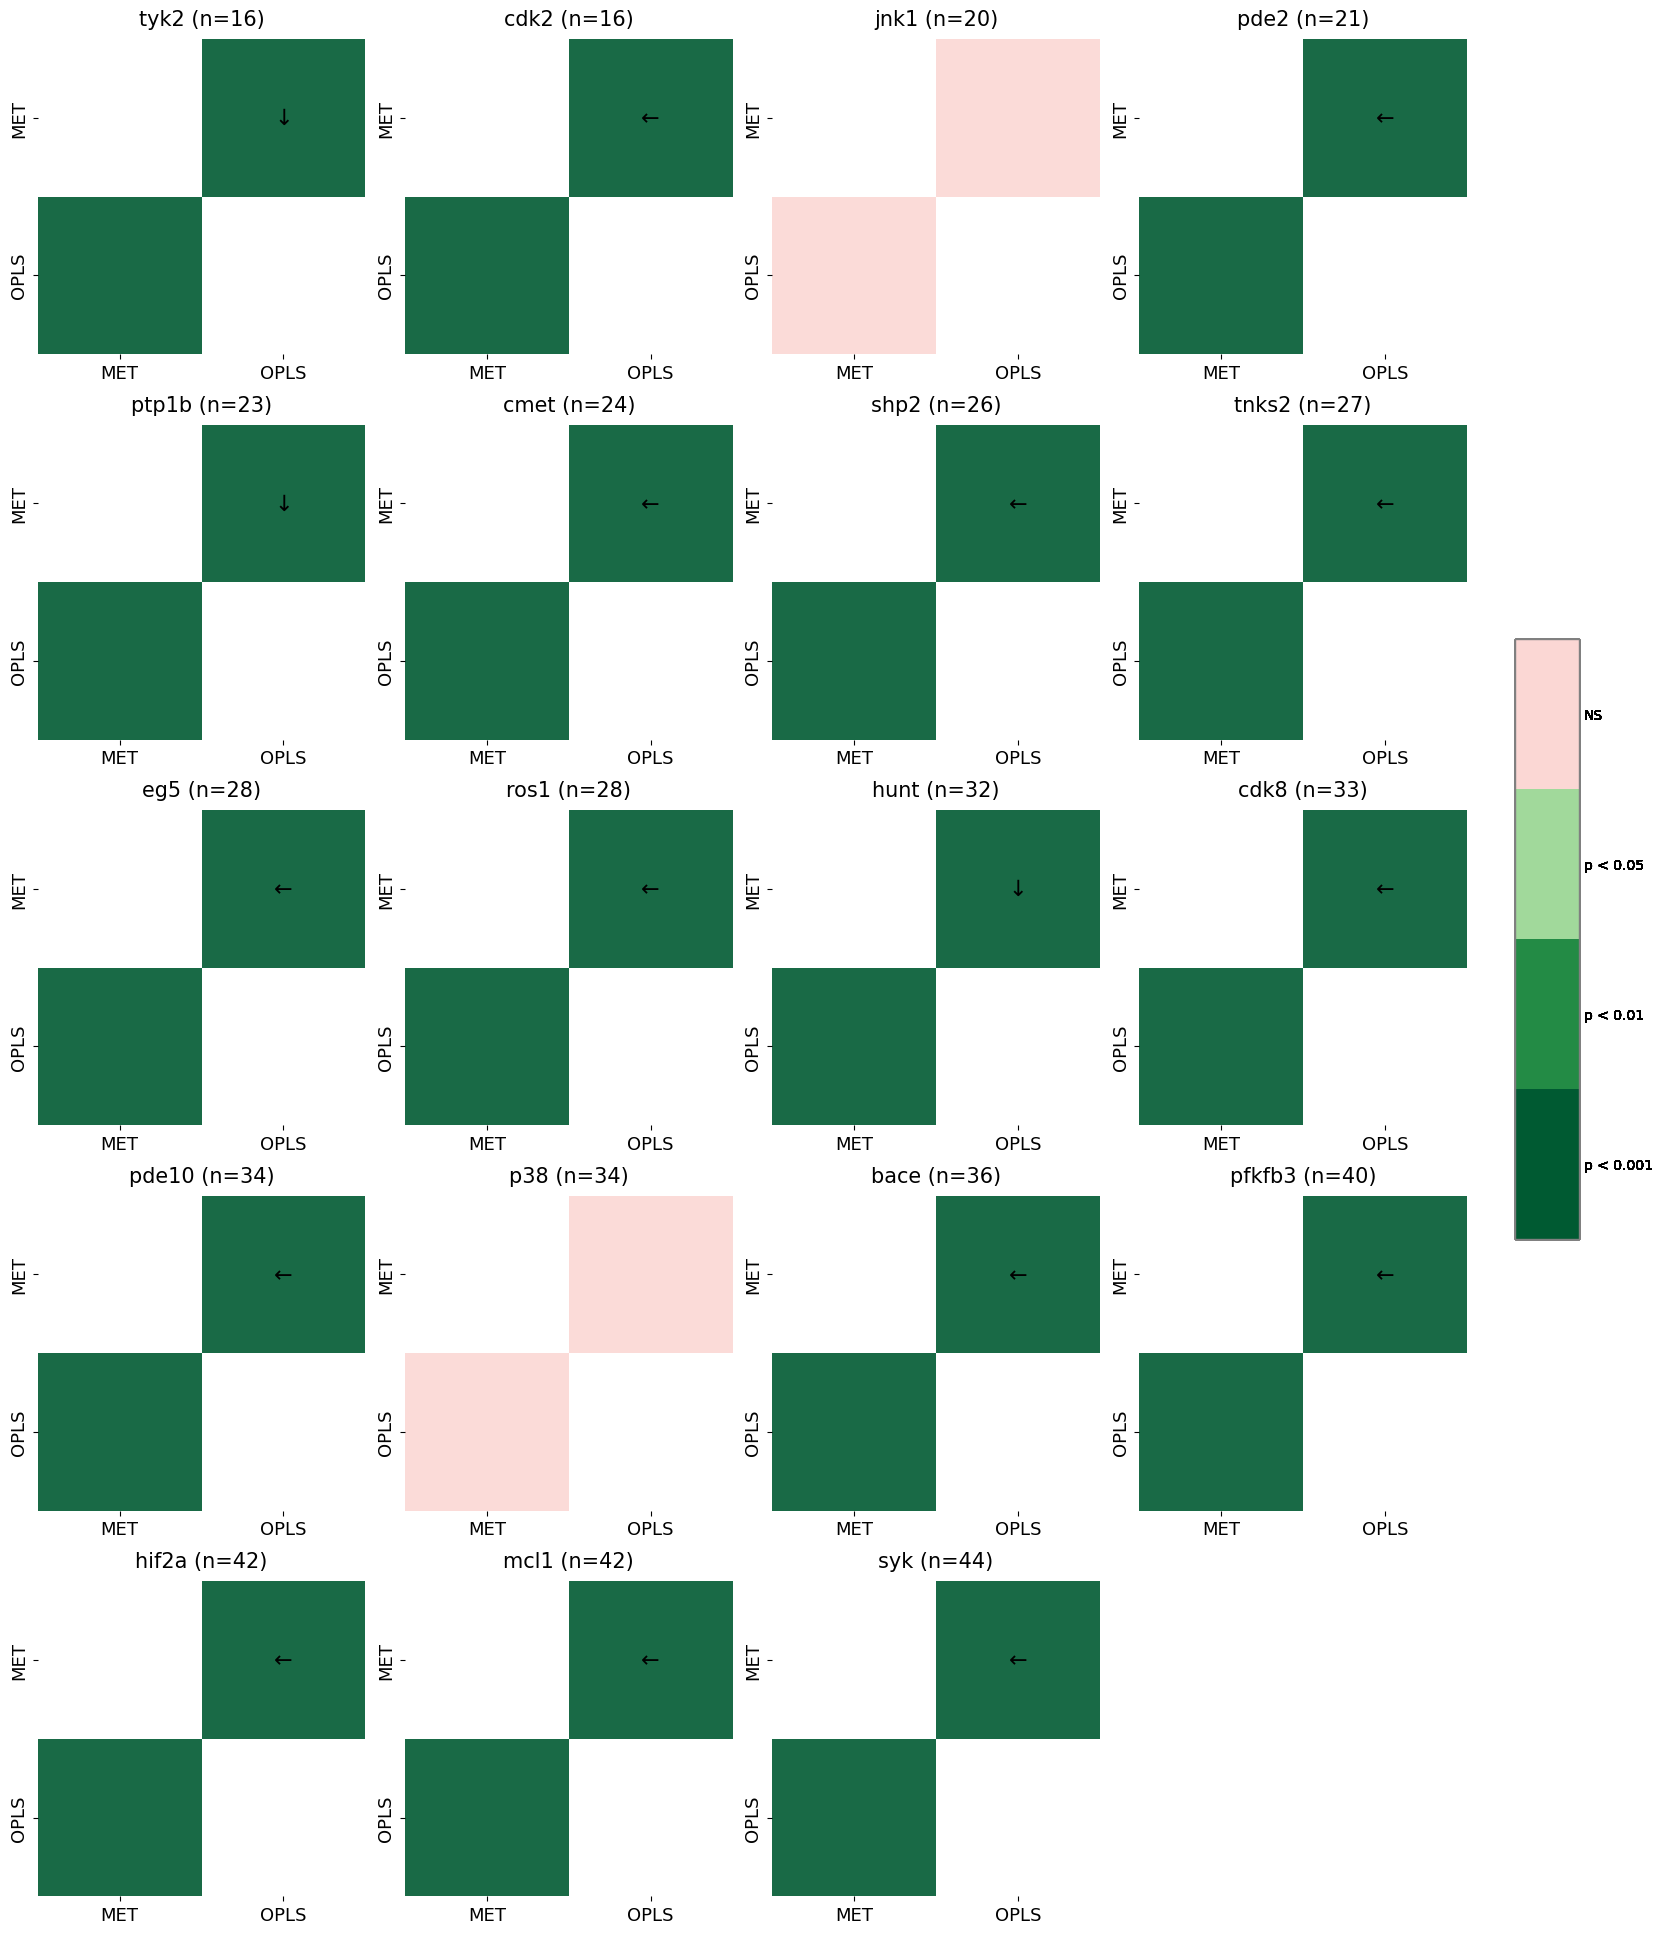

kendalls_tau significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/WINS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


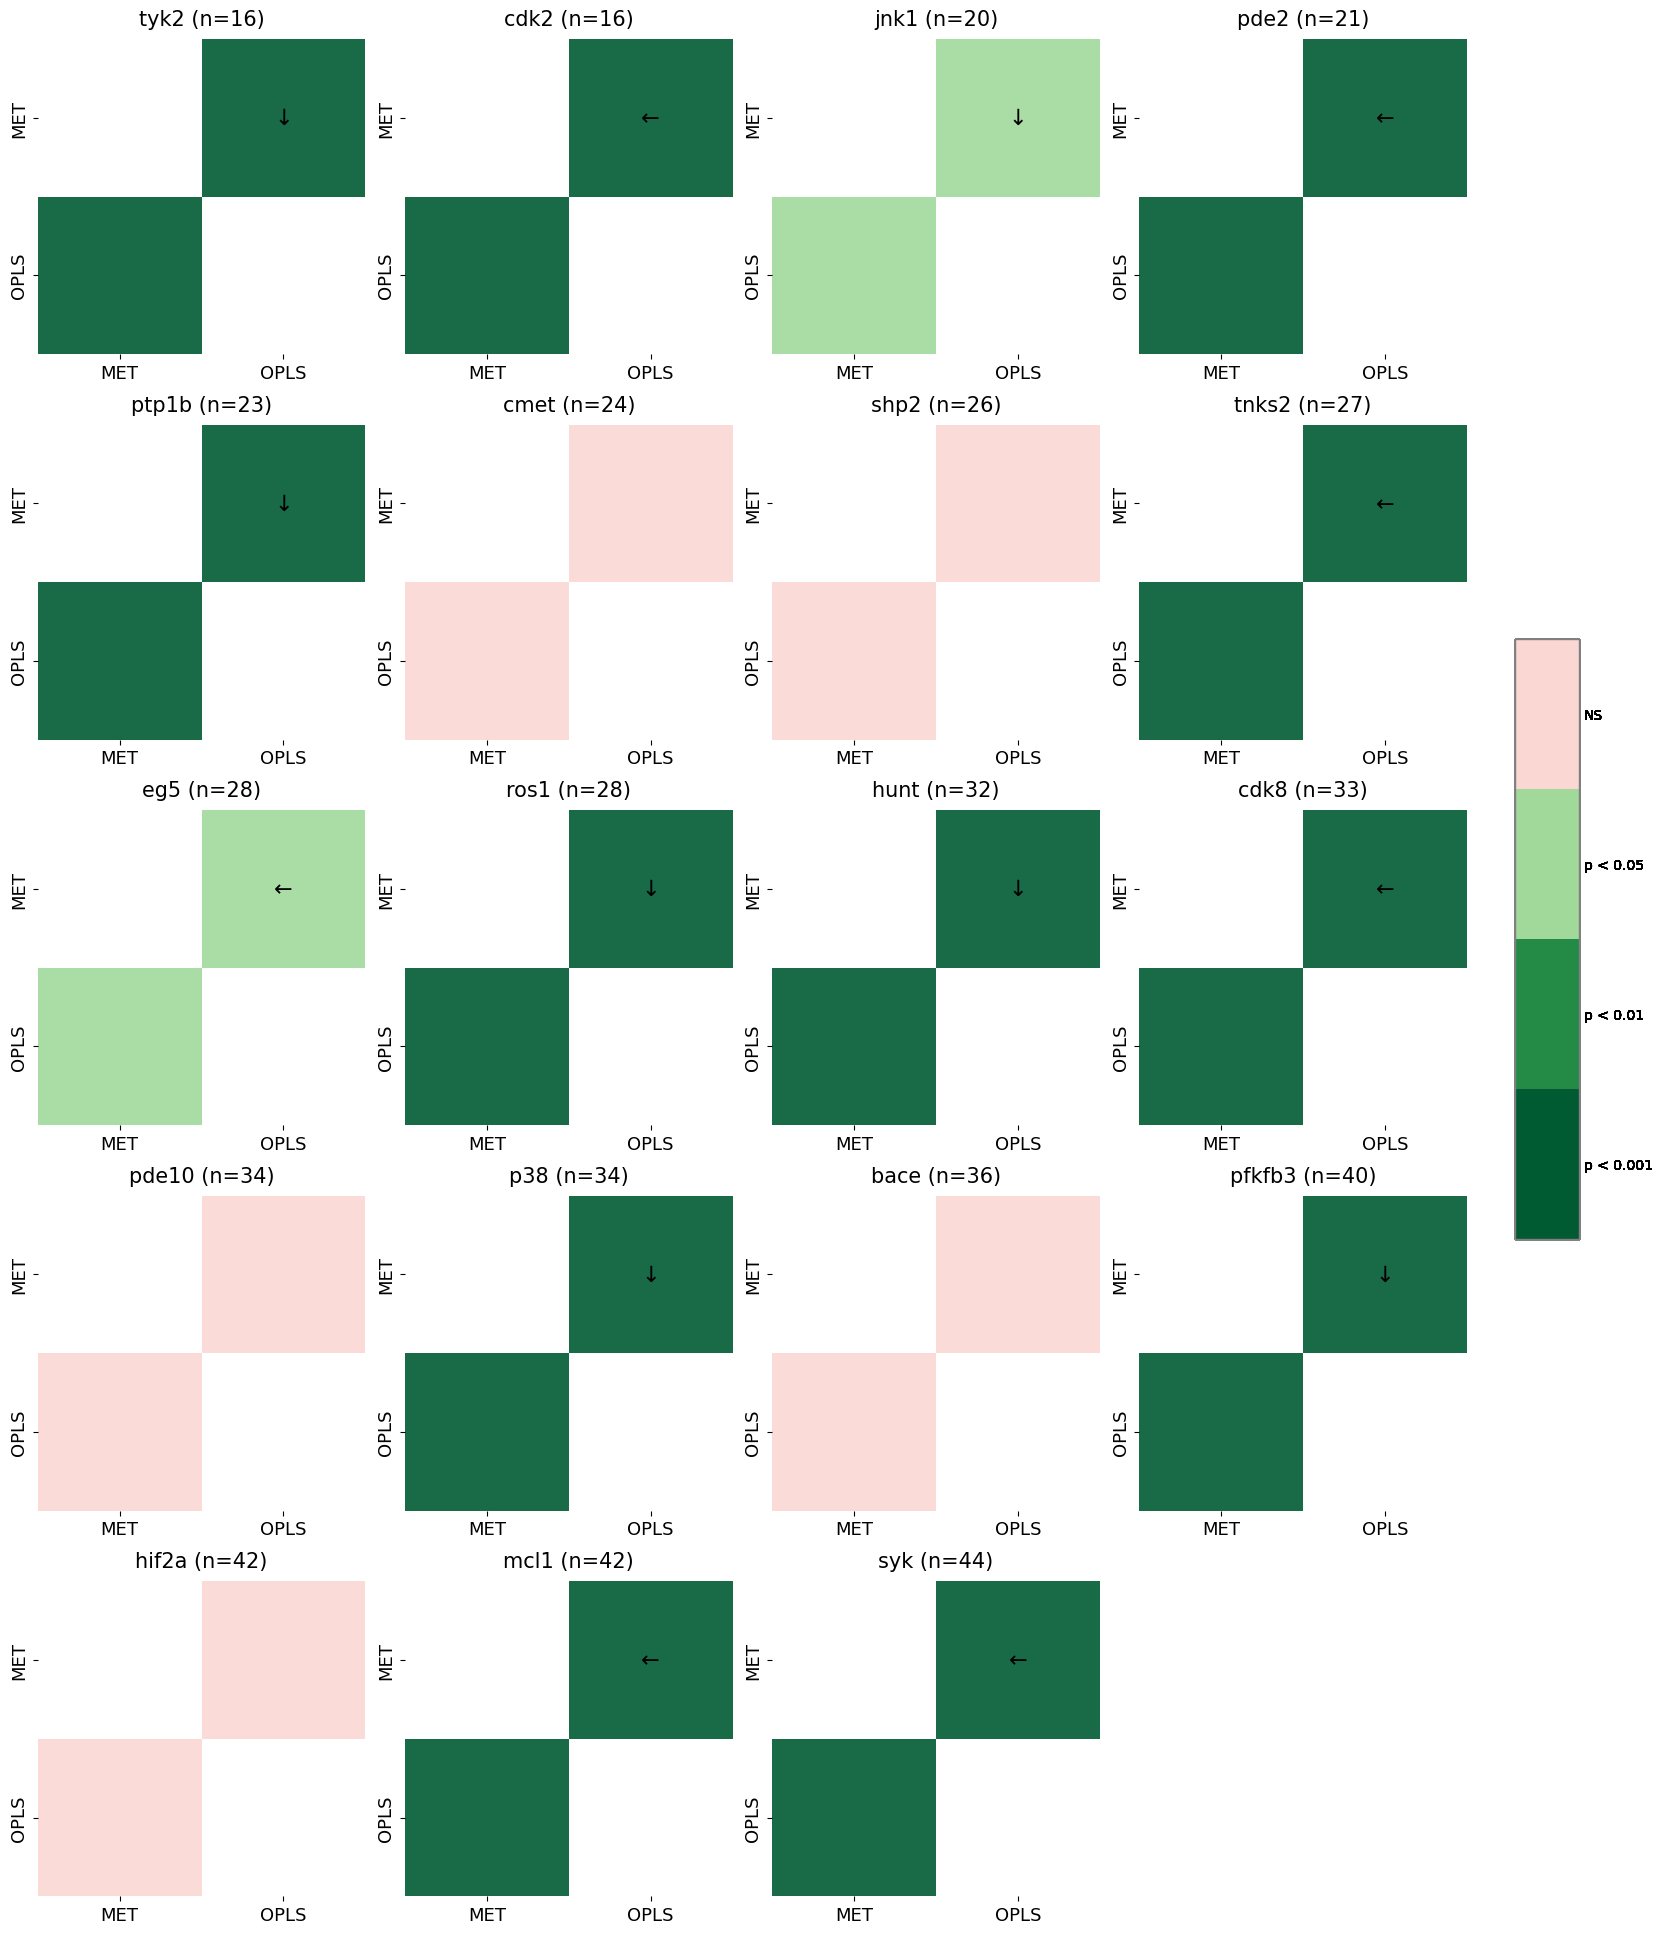

window_tau significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/WINS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


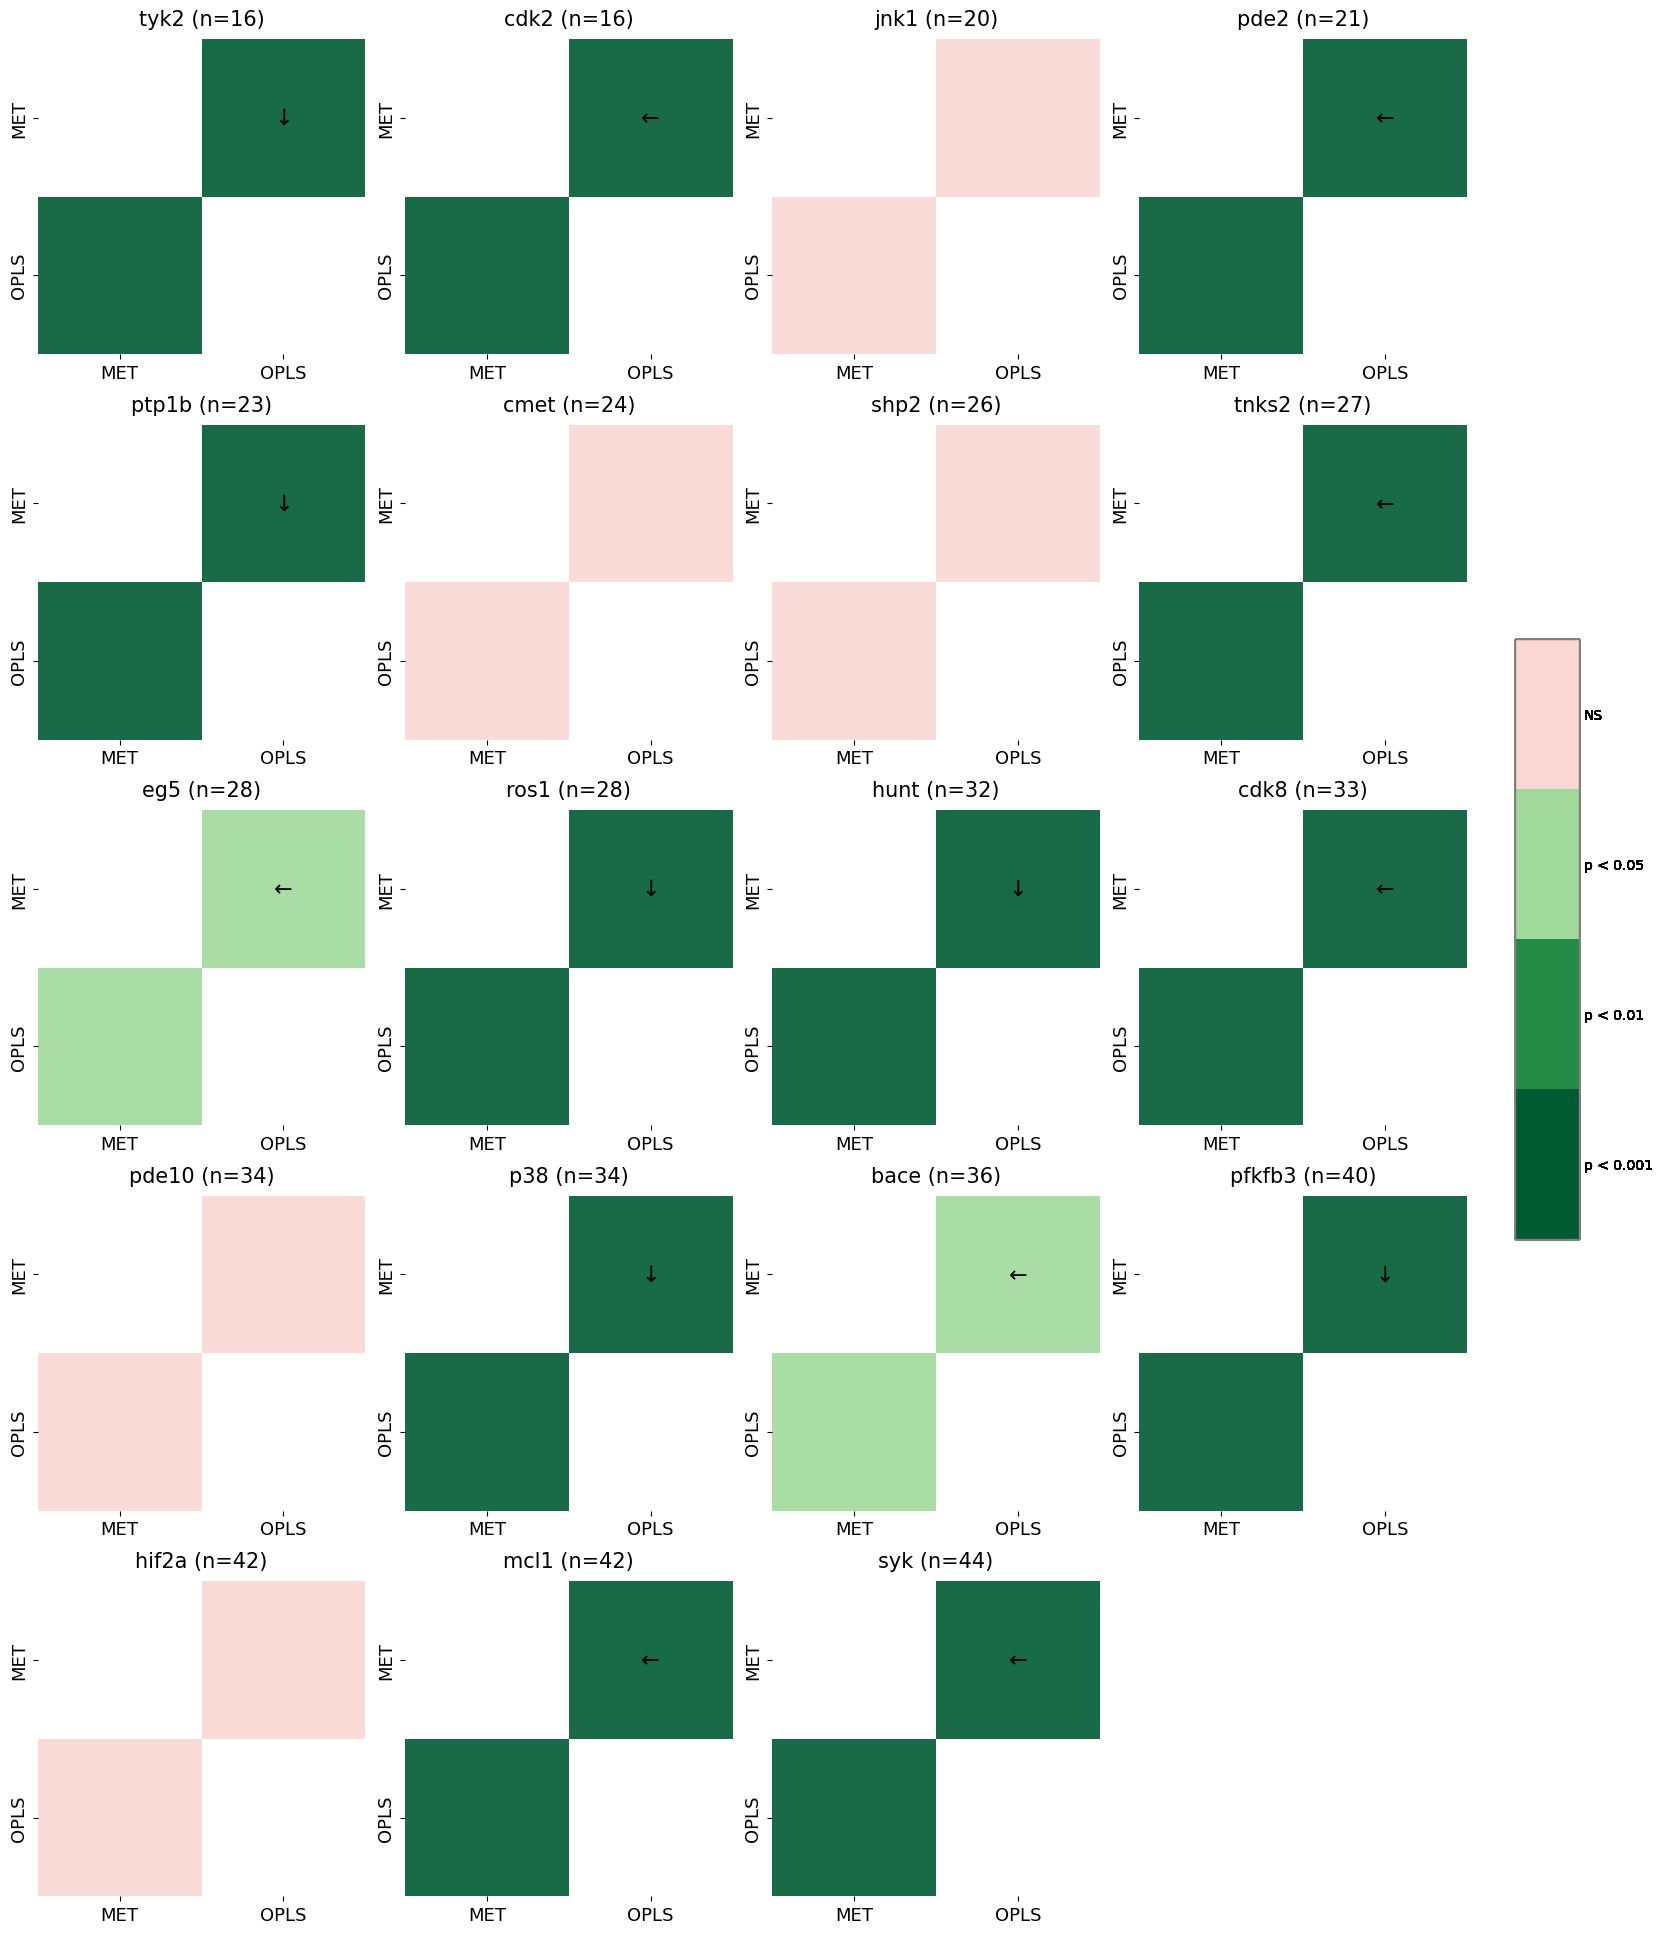

slope_diff significance by target


/home/schrin/MASTERS_THESIS_STEFAN_CHRIN_PAPER_RERUNZZ_DEPTH_5_FINAL_PAPER/ZZ_MA_FROM_GITLAB/TEST_COPY_FINAL_REPO_AND_COMPARE/ml_vs_fep/B_COMPARE_METHODS/DDG/WINS/../../../SRC/DDG_ANALYSIS/D_WILCOXON.py:205: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


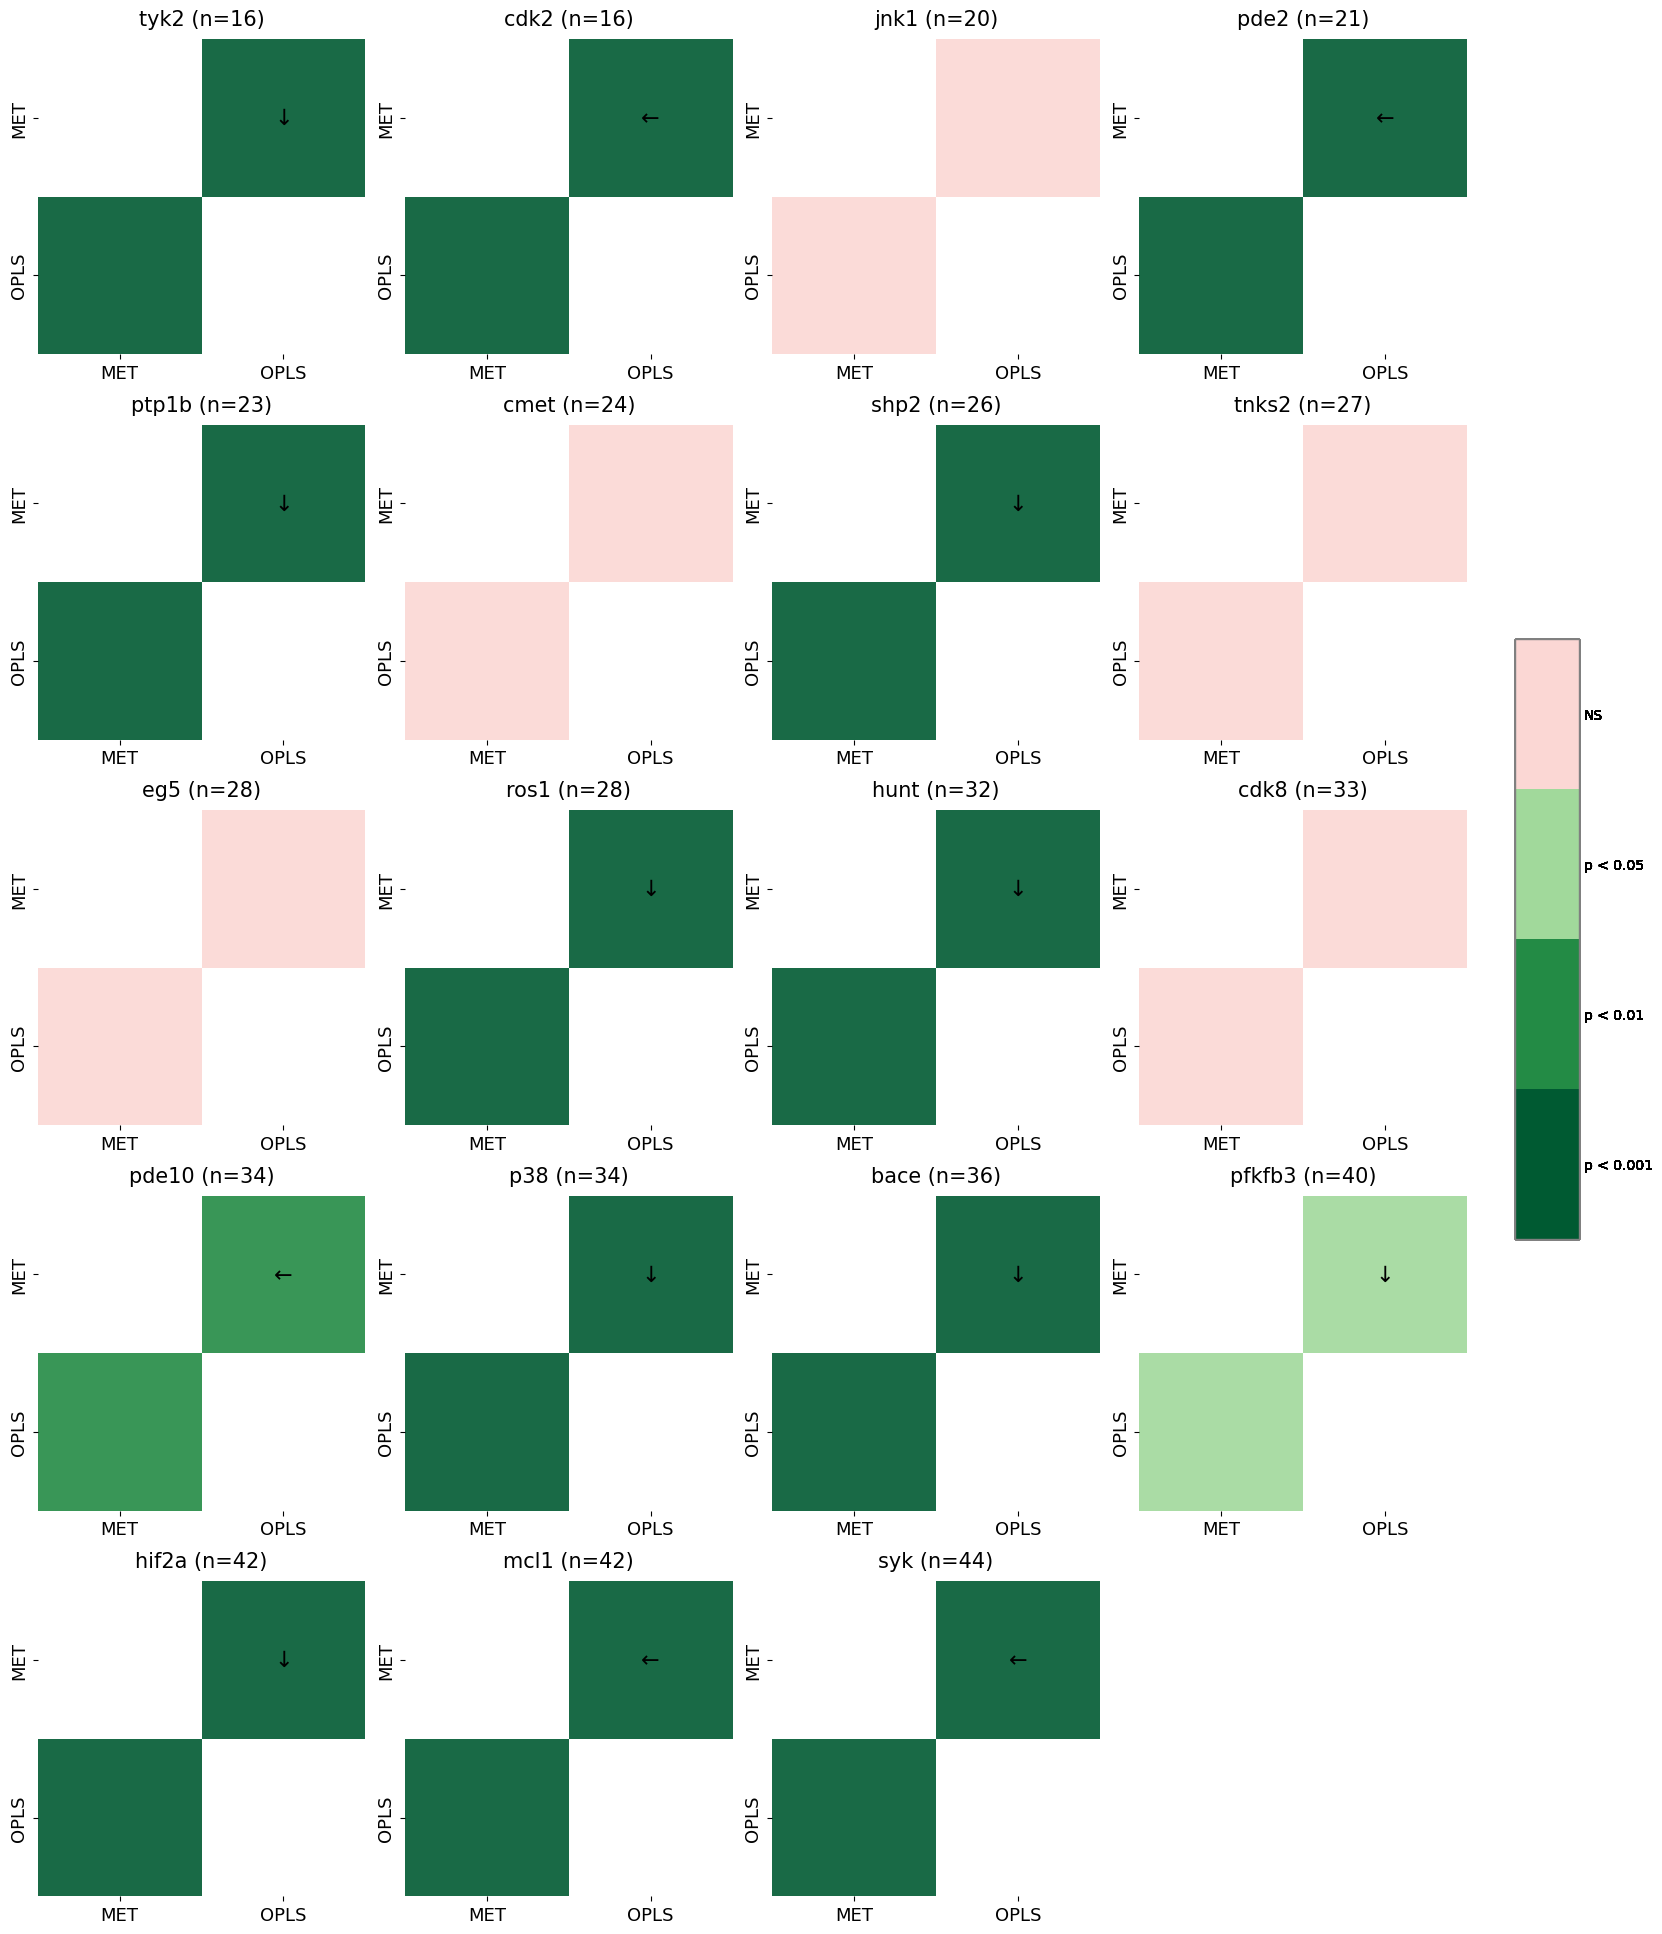

In [5]:
from DDG_ANALYSIS.D_WILCOXON import sign_plot
sign_plot(
    results_all,
    wilcox_posthoc_results,
    DISPLAY_ORDER,
    target_counts_path=target_counts_path,
    metrics=METRICS,
    targets_to_skip=TARGETS_TO_SKIP,
    n_cols=4,
    arrow_threshold=0.05, # This is the p value for an arrow to show, should be in accordance with the legend (green -> has an arrow)
    alpha=0.9, # this alpha is how seethrough plot is, not to be mixed up with ALPHA (p value)
)

### Effect size & Significance (Based on wilcoxon)

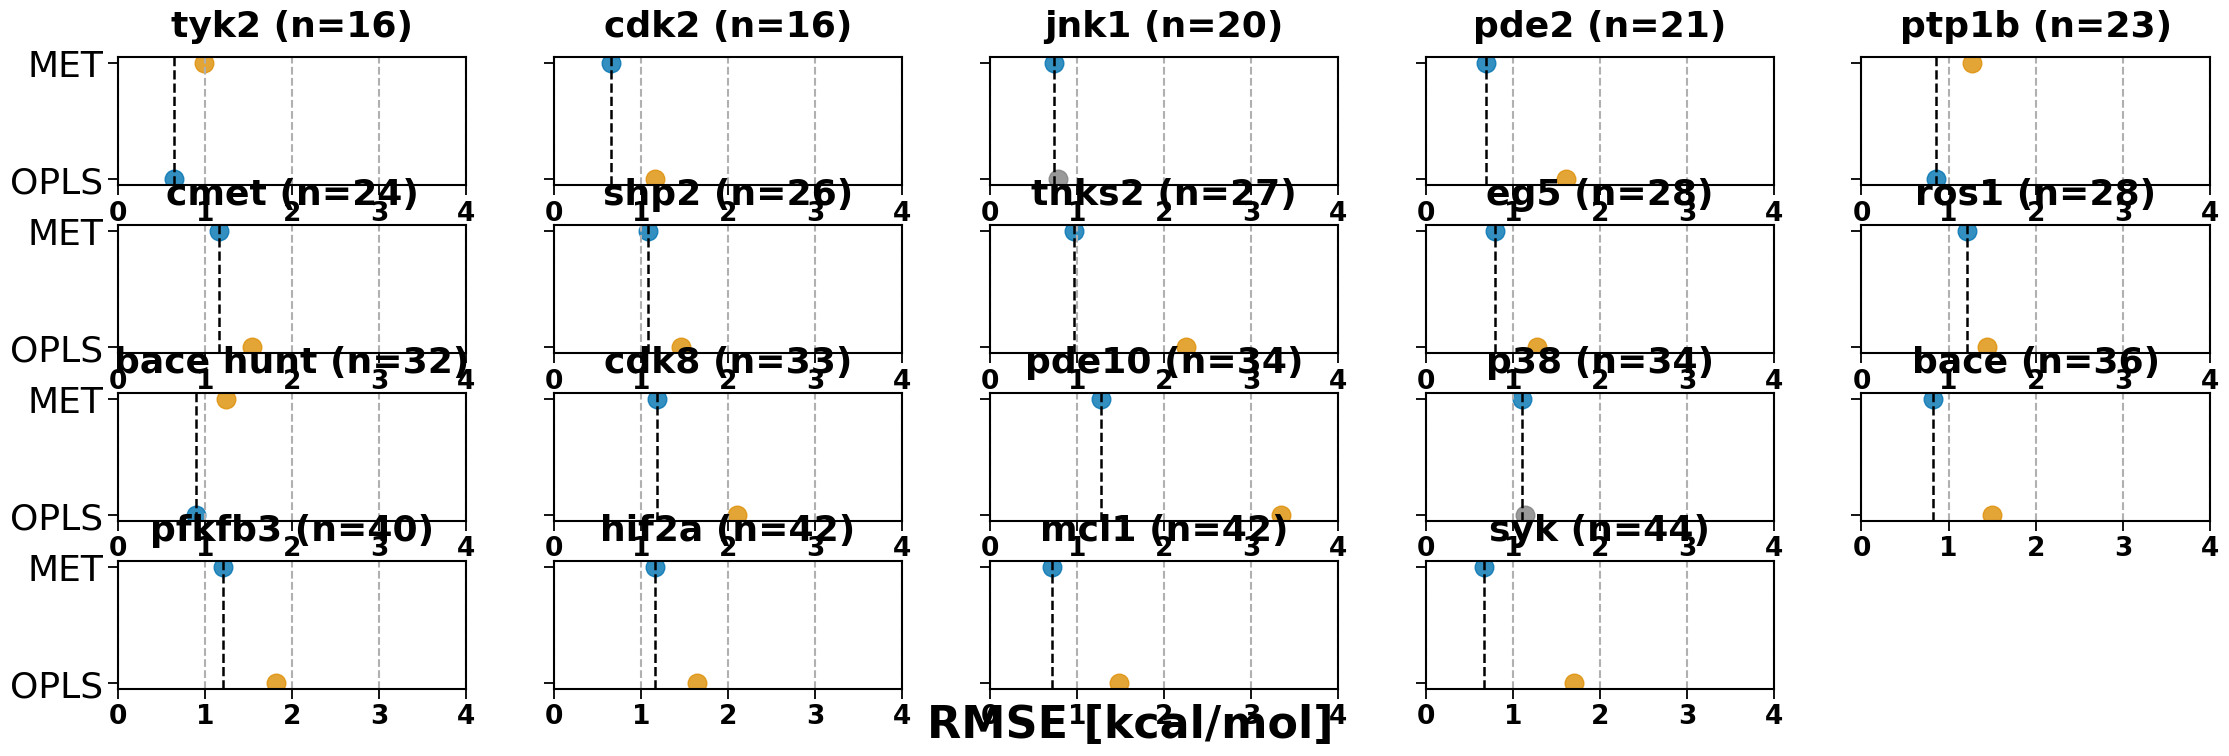


Effect-size counts for metric 'rmse':
- MET: 11 targets → ['cdk2', 'pde2', 'tnks2', 'eg5', 'cdk8', 'pde10', 'bace', 'pfkfb3', 'hif2a', 'mcl1', 'syk']
- OPLS: 1 targets → ['ptp1b']


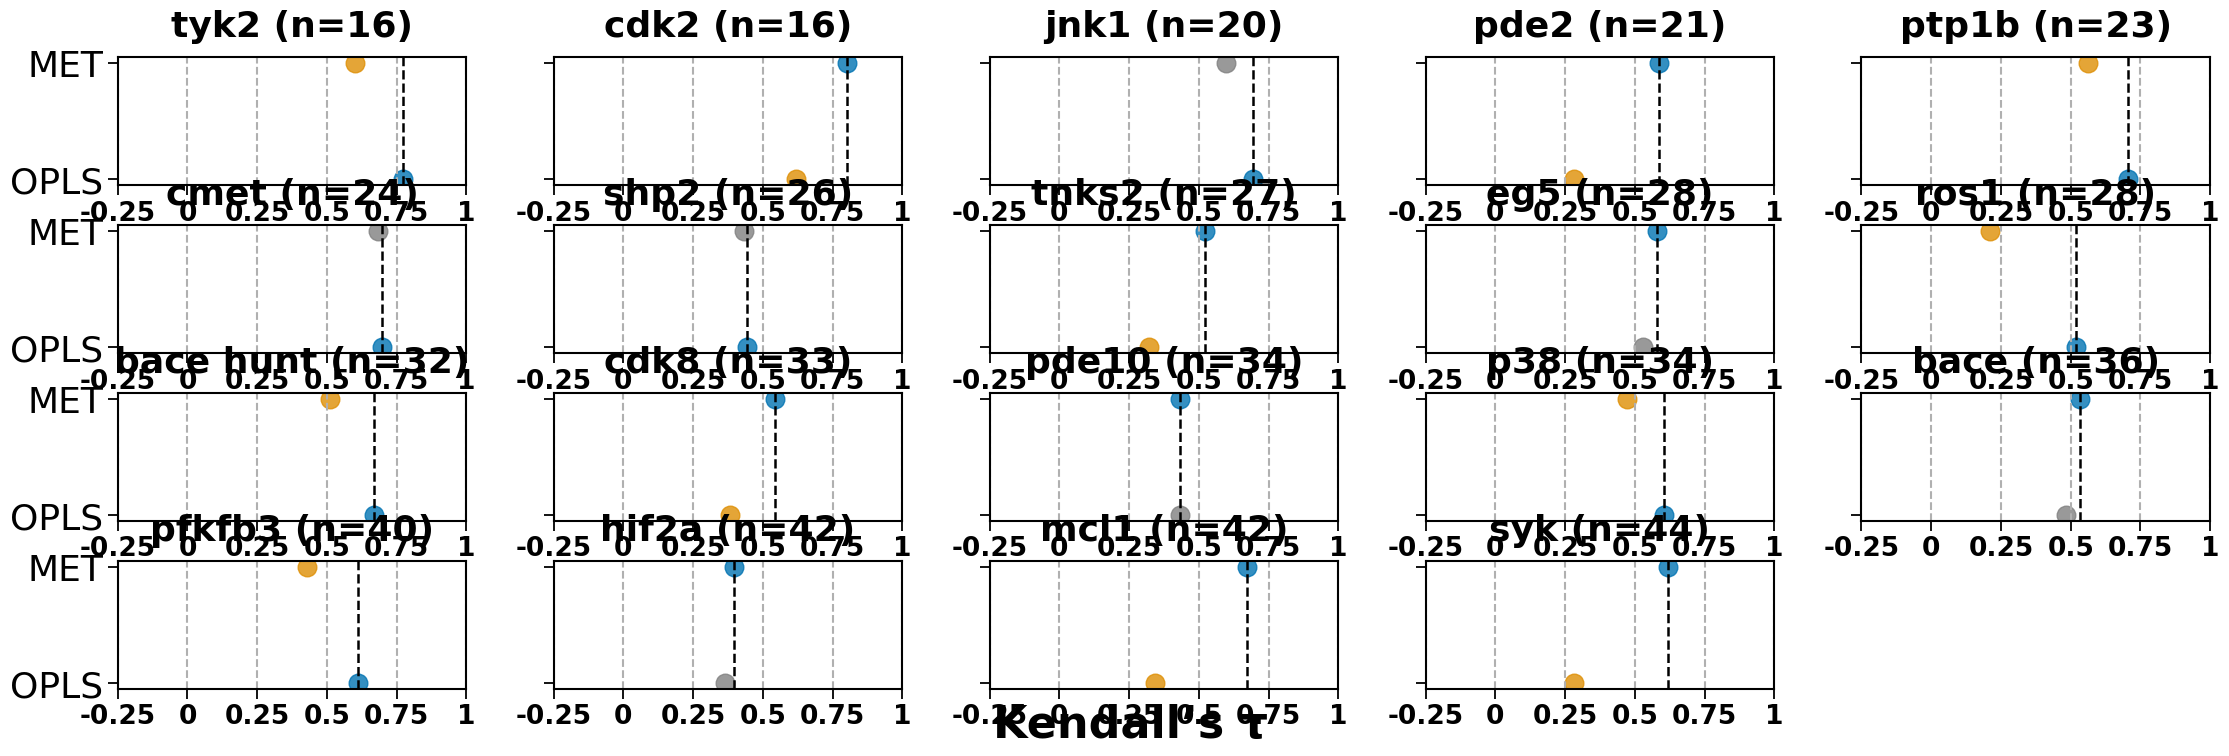


Effect-size counts for metric 'kendalls_tau':
- MET: 4 targets → ['pde2', 'tnks2', 'mcl1', 'syk']
- OPLS: 1 targets → ['ros1']


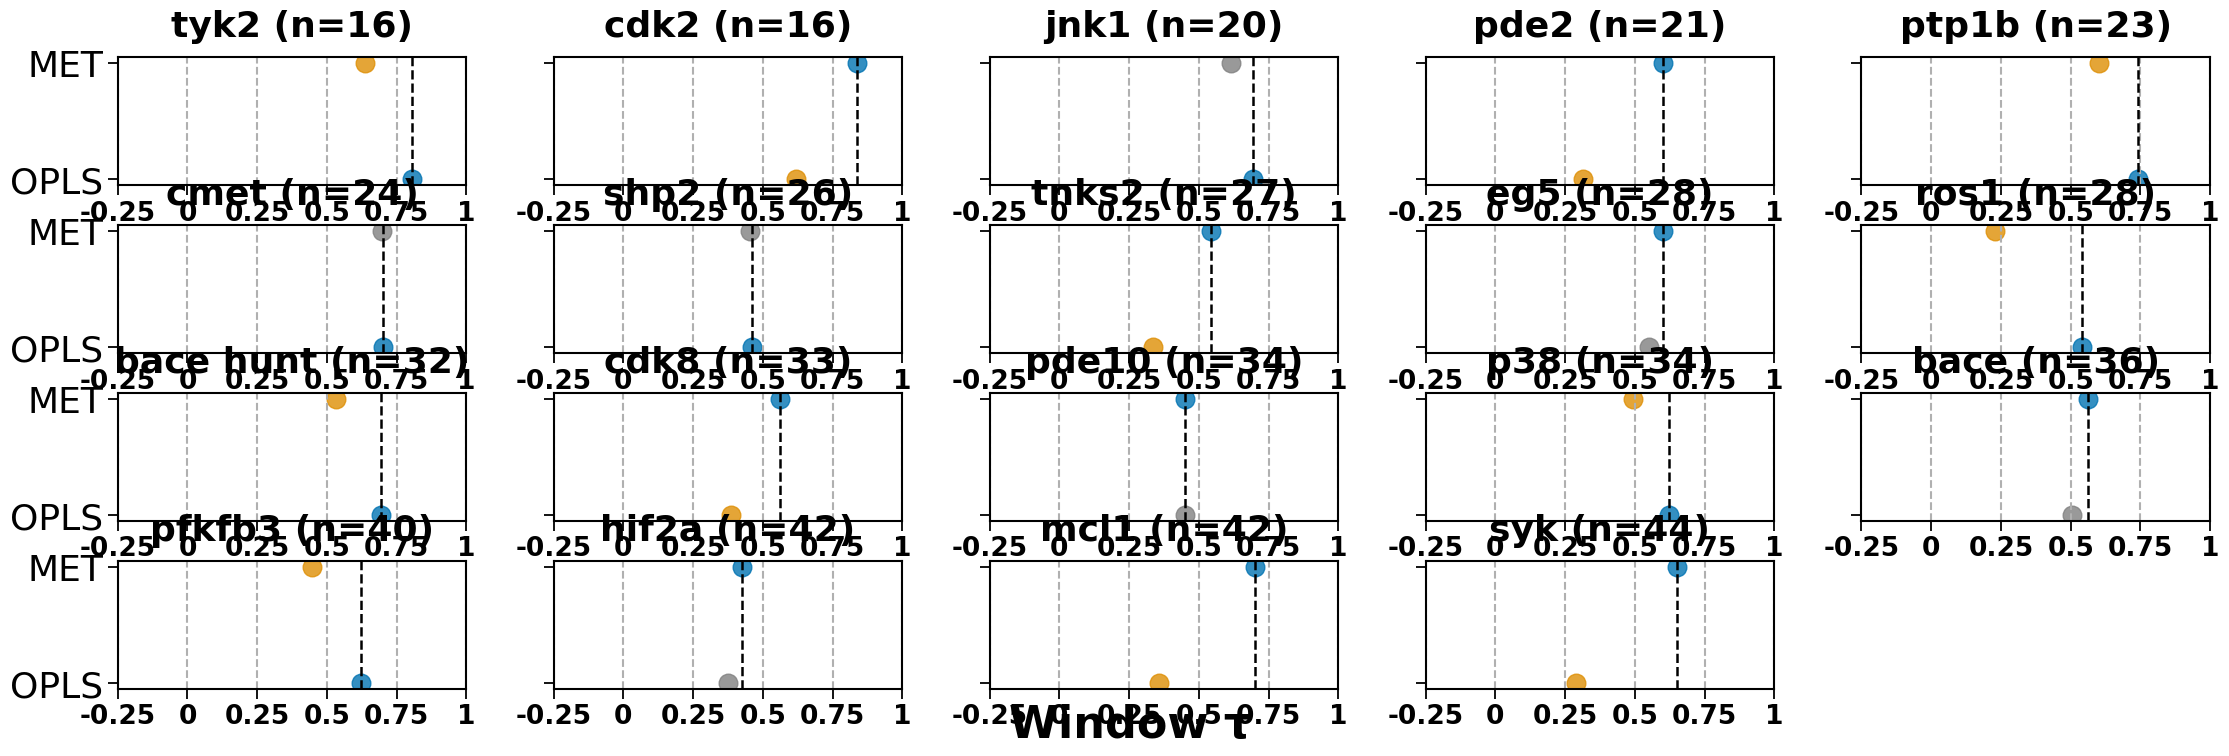


Effect-size counts for metric 'window_tau':
- MET: 5 targets → ['cdk2', 'pde2', 'tnks2', 'mcl1', 'syk']
- OPLS: 1 targets → ['ros1']


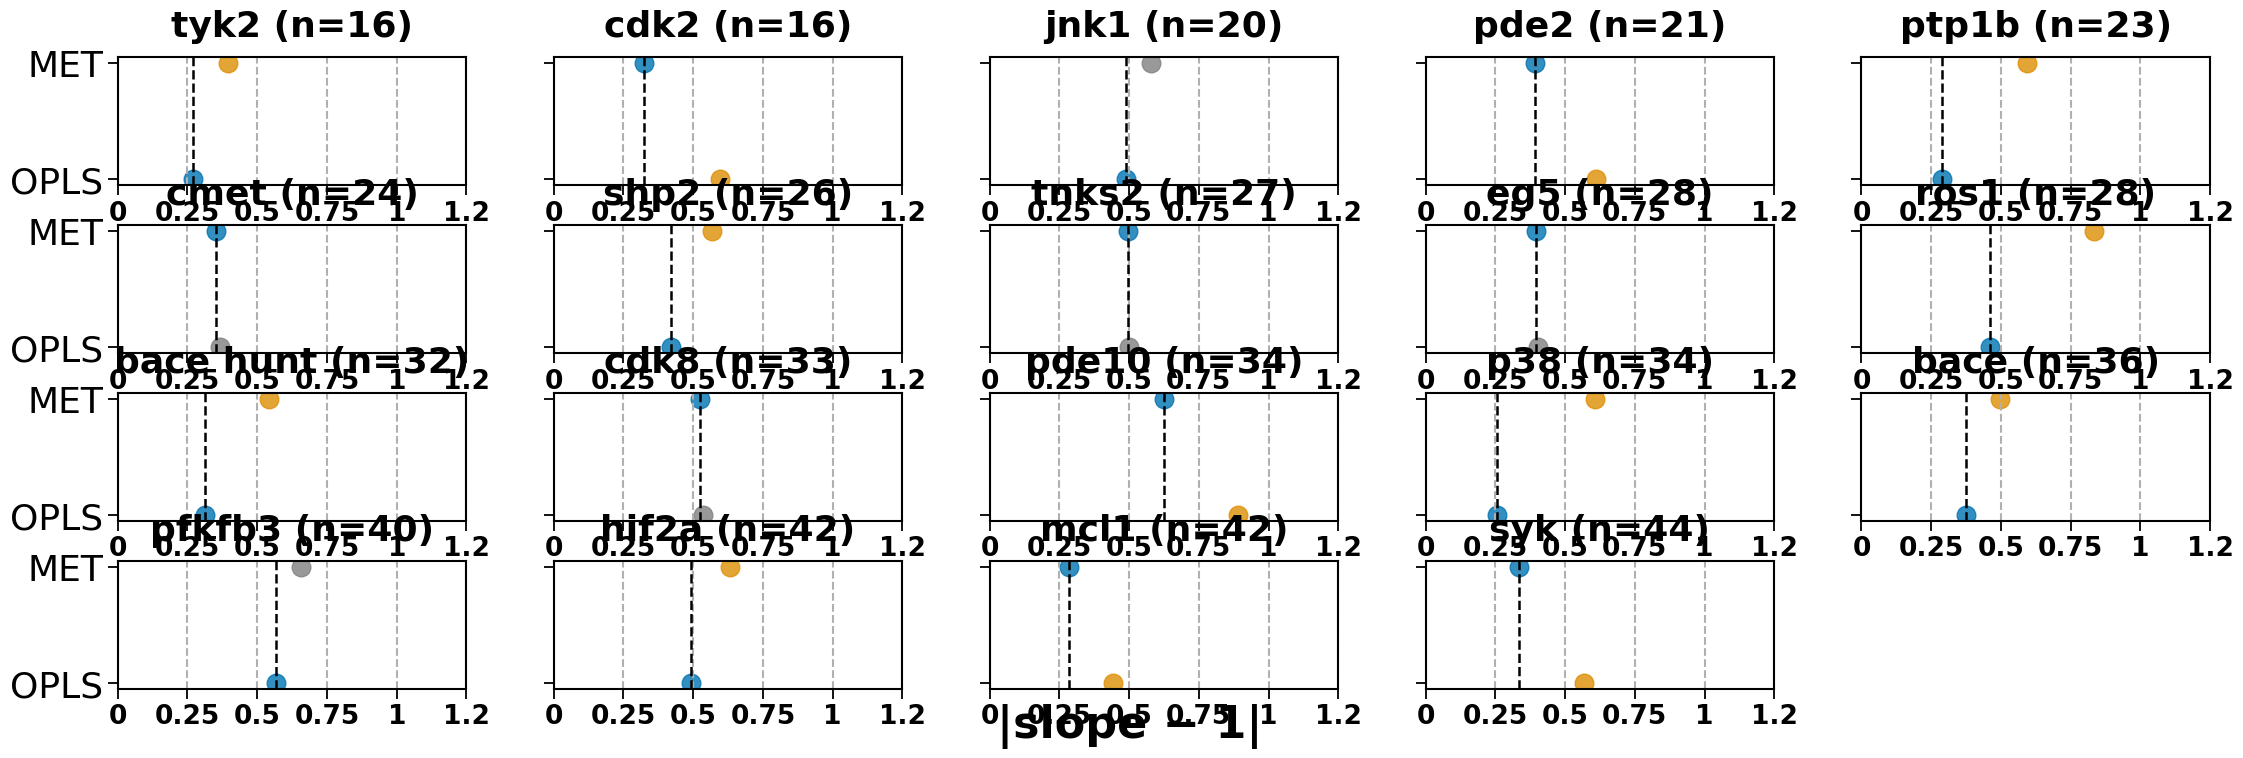


Effect-size counts for metric 'slope_diff':
- MET: 2 targets → ['cdk2', 'pde10']
- OPLS: 3 targets → ['ptp1b', 'ros1', 'p38']


In [6]:
from DDG_ANALYSIS.E_EFFECT_SIZE_PLOT import plot_significance_ranks
plot_significance_ranks(results_all, DISPLAY_ORDER, ALPHA=ALPHA, METRICS=METRICS, target_counts_path=target_counts_path, COUNT_EFFECTS=True)